# 05 — Models: random search inside rolling-origin folds

Fits **ridge regression, random forest and gradient boosting** at horizons of **1, 3, 6 and 12 months**, tuned by random search on the five validation folds, and compares them with the best-tuned naive baseline. **The locked 2021–2025 test set is never scored here.**

**Target:** log(1 + state-based deaths) at the target month. **Features:** the 28 columns from notebook 04, known at the origin month.

### Rules that keep the comparison fair
- **Every model family gets the same budget:** `N_ITER` random configurations, drawn with the same seed.
- **The naive baseline is tuned too:** its one hyperparameter, the averaging window, is searched over 1–24 months.
- **Selection:** the configuration with the lowest mean RMSE across folds 1–5. Because selection and reporting use the same folds, the reported numbers are mildly optimistic; the locked test set, scored once at the end, is the honest number.
- **Training rows for a fold** are those whose target month is on or before the fold's `train_end`.

### Running it
`QUICK_TEST = True` runs a tiny version (horizon 1, 2 configurations, subsampled rows) to check everything works. For the real run set it to `False`; progress is saved to `results/tuning_log.csv` after every block, so an interrupted run resumes where it stopped.

### What is scored
- **RMSE and MAE** on the log scale, over all validation rows and by row type (stay quiet / onset / continuation / cessation, using ≥ 1 death as "conflict").
- **Onset detection:** among *at-risk* rows (quiet for `M_ONSET` months at the origin), how well the predicted value ranks the rows that reach `K_ONSET` or more deaths, measured by average precision (area under the precision–recall curve), pooled over folds 1–5.

## Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path

root = Path.cwd().resolve()
while not (root / ".git").exists():
    if root == root.parent:
        raise FileNotFoundError("Open this notebook from inside the DACSS_ML_FP repo.")
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import average_precision_score
from sklearn.model_selection import ParameterSampler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.paths import PROCESSED, ROOT
from src.features.build import FEATURES
from src.eval.splits import FOLDS, make_supervised, fold_masks
from src.eval.metrics import rmse, mae, transition_type, score

# ------------------------------------------------------------------ settings
QUICK_TEST = False          # True = tiny smoke test (see above)
HORIZONS = [1, 3, 6, 12]
N_ITER = 40                 # random configurations per model family (same for every family)
SEED = 42
K_ONSET, M_ONSET = 25, 6    # onset definition (matches notebook 04)
CONFLICT_MIN = 1.0
NAIVE_WINDOWS = [1, 2, 3, 4, 6, 9, 12, 18, 24]

if QUICK_TEST:
    HORIZONS, N_ITER = [1], 2
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)
LOG_PATH = RESULTS / ("tuning_log_quicktest.csv" if QUICK_TEST else "tuning_log.csv")
pd.set_option("display.width", 150, "display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

COLORS = {"naive (best window)": "#8a8a85", "ridge": "#2a78d6", "random forest": "#eb6834", "gradient boosting": "#1baf7a"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5f5e5a",
    "ytick.color": "#5f5e5a", "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 1.8, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})
print(f"QUICK_TEST={QUICK_TEST}  horizons={HORIZONS}  N_ITER={N_ITER}  log -> {LOG_PATH.relative_to(ROOT)}")

QUICK_TEST=False  horizons=[1, 3, 6, 12]  N_ITER=40  log -> results\tuning_log.csv


## 1. Data

One table per horizon: features at the origin month, target `horizon` months later. Only `usable` origins are kept (full 12-month history, all V-Dem indices present). Fold masks come from `src/eval/splits.py`.

In [2]:
feat = pd.read_parquet(PROCESSED / "features.parquet")

def table(h: int) -> pd.DataFrame:
    d = make_supervised(feat, horizon=h)
    d = d[d["usable"]].reset_index(drop=True)
    d["event"] = d["at_risk"] & (d["raw_y"] >= K_ONSET)
    d["now_conflict"] = d["sb_best"] >= CONFLICT_MIN
    d["next_conflict"] = d["raw_y"] >= CONFLICT_MIN
    d["kind"] = transition_type(d["now_conflict"], d["next_conflict"])
    return d

TABLES = {h: table(h) for h in HORIZONS}
for h, d in TABLES.items():
    tr, va = fold_masks(d, FOLDS[-1])
    print(f"horizon {h:>2}: {len(d):,} rows;  fold 5 trains on {int(tr.sum()):,} rows, validates on {int(va.sum()):,}")

if QUICK_TEST:   # subsample training rows for speed (smoke test only)
    rng = np.random.default_rng(SEED)
    for h in TABLES:
        d = TABLES[h]; keep = rng.random(len(d)) < 0.25
        TABLES[h] = d[keep].reset_index(drop=True)
    print("QUICK_TEST: rows subsampled to 25%")

horizon  1: 71,904 rows;  fold 5 trains on 55,488 rows, validates on 6,156
horizon  3: 71,554 rows;  fold 5 trains on 55,138 rows, validates on 6,156
horizon  6: 71,030 rows;  fold 5 trains on 54,614 rows, validates on 6,156
horizon 12: 69,988 rows;  fold 5 trains on 53,572 rows, validates on 6,156


## 2. Models and search spaces

Same number of random draws for each family. Ranges are wide on purpose, since random search wastes little on irrelevant parameters (Bergstra & Bengio 2012).

| Family | Searched hyperparameters |
|---|---|
| Ridge (standardised inputs) | `alpha` (log-uniform 1e-3 … 1e4) |
| Random forest | trees, depth, min samples per leaf, features per split, bootstrap fraction |
| Gradient boosting (histogram-based) | learning rate, iterations, depth, leaves, min samples per leaf, L2 penalty, features per split |

In [ ]:
FAMILIES = {
    "ridge": (
        make_pipeline(StandardScaler(), Ridge()),
        {"ridge__alpha": loguniform(1e-3, 1e4)},
    ),
    "random forest": (
        RandomForestRegressor(n_jobs=-1, random_state=SEED),
        {"n_estimators": randint(100, 400), "max_depth": [4, 6, 8, 12, 16, 24, None],
         "min_samples_leaf": randint(1, 60), "max_features": uniform(0.2, 0.7),
         "max_samples": uniform(0.3, 0.7)},
    ),
    "gradient boosting": (
        HistGradientBoostingRegressor(random_state=SEED),
        {"learning_rate": loguniform(0.01, 0.3), "max_iter": randint(100, 600),
         "max_depth": [3, 4, 6, 8, None], "max_leaf_nodes": randint(8, 64),
         "min_samples_leaf": randint(10, 200), "l2_regularization": loguniform(1e-3, 10),
         "max_features": uniform(0.3, 0.7)},
    ),
}
# Identical draws for every horizon (seeded per family), so horizons are comparable.
CONFIGS = {name: list(ParameterSampler(space, n_iter=N_ITER, random_state=SEED))
           for name, (est, space) in FAMILIES.items()}
print({k: len(v) for k, v in CONFIGS.items()}, "configurations per family")
print("Example gradient-boosting draw:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in CONFIGS["gradient boosting"][0].items()})

{'ridge': 40, 'random forest': 40, 'gradient boosting': 40} configurations per family
Example gradient-boosting draw: {'l2_regularization': np.float64(0.0315), 'learning_rate': np.float64(0.2537), 'max_depth': 6, 'max_features': np.float64(0.8458), 'max_iter': 120, 'max_leaf_nodes': 46, 'min_samples_leaf': 131}


## 3. Search

For each horizon and family, every configuration is fitted on each fold's training rows and scored on that fold's validation rows. The log is saved after each (horizon, family) block; blocks already in the log are skipped, so the cell can be re-run after an interruption.

In [4]:
def to_native(v):
    return v.item() if hasattr(v, "item") else v

def run_search(h: int, name: str) -> pd.DataFrame:
    est, _ = FAMILIES[name]
    d = TABLES[h]
    X = d[FEATURES].to_numpy(float); y = d["y"].to_numpy(float)
    masks = [fold_masks(d, f) for f in FOLDS]
    rows = []
    for i, cfg in enumerate(CONFIGS[name]):
        for f, (tr, va) in zip(FOLDS, masks):
            m = clone(est).set_params(**cfg).fit(X[tr], y[tr])
            p = m.predict(X[va])
            rows.append({"horizon": h, "family": name, "config_id": i, "fold": f.name,
                         "rmse": rmse(y[va], p), "mae": mae(y[va], p),
                         "params": json.dumps({k: to_native(v) for k, v in cfg.items()})})
    return pd.DataFrame(rows)

log = pd.read_csv(LOG_PATH) if LOG_PATH.exists() else pd.DataFrame()
t0 = time.time()
for h in HORIZONS:
    for name in FAMILIES:
        done = len(log) and ((log["horizon"] == h) & (log["family"] == name)).any()
        if done:
            print(f"[skip] horizon {h}, {name}: already in log"); continue
        block = run_search(h, name)
        log = pd.concat([log, block], ignore_index=True)
        log.to_csv(LOG_PATH, index=False)
        best = block.groupby("config_id")["rmse"].mean().min()
        print(f"[done] horizon {h:>2}  {name:<18} best mean RMSE {best:.4f}   ({(time.time() - t0) / 60:.1f} min elapsed)")
print("Search complete." )

[done] horizon  1  ridge              best mean RMSE 0.5033   (0.1 min elapsed)
[done] horizon  1  random forest      best mean RMSE 0.5048   (4.8 min elapsed)
[done] horizon  1  gradient boosting  best mean RMSE 0.5073   (5.9 min elapsed)
[done] horizon  3  ridge              best mean RMSE 0.5707   (6.0 min elapsed)
[done] horizon  3  random forest      best mean RMSE 0.5783   (10.7 min elapsed)
[done] horizon  3  gradient boosting  best mean RMSE 0.5824   (12.2 min elapsed)
[done] horizon  6  ridge              best mean RMSE 0.6216   (12.3 min elapsed)
[done] horizon  6  random forest      best mean RMSE 0.6322   (16.7 min elapsed)
[done] horizon  6  gradient boosting  best mean RMSE 0.6354   (18.7 min elapsed)
[done] horizon 12  ridge              best mean RMSE 0.6887   (18.9 min elapsed)
[done] horizon 12  random forest      best mean RMSE 0.7012   (23.2 min elapsed)
[done] horizon 12  gradient boosting  best mean RMSE 0.7101   (25.5 min elapsed)
Search complete.


## 4. Naive baseline, tuned the same way

The prediction is the mean of the last *w* months of log(1 + state-based deaths), with *w* searched over `NAIVE_WINDOWS` (w = 1 is persistence). The best window is chosen on mean RMSE across folds 1–5, exactly like the models.

In [5]:
def naive_pred(d: pd.DataFrame, w: int) -> np.ndarray:
    # Rolling mean of the state's own log deaths ending at the origin month. The origin
    # table does not carry every window, so rebuild it from the feature table's raw deaths.
    base = feat[["gwno", "month", "sb_best"]].copy()
    base["ls"] = np.log1p(base["sb_best"])
    base = base.sort_values(["gwno", "month"])
    base["pred"] = base.groupby("gwno")["ls"].transform(lambda s: s.rolling(w, min_periods=1).mean())
    return d[["gwno", "month"]].merge(base[["gwno", "month", "pred"]], on=["gwno", "month"], how="left")["pred"].to_numpy()

naive_rows = []
for h in HORIZONS:
    d = TABLES[h]; y = d["y"].to_numpy(float)
    masks = [fold_masks(d, f)[1] for f in FOLDS]
    for w in NAIVE_WINDOWS:
        p = naive_pred(d, w)
        for f, va in zip(FOLDS, masks):
            naive_rows.append({"horizon": h, "window": w, "fold": f.name, "rmse": rmse(y[va], p[va]), "mae": mae(y[va], p[va])})
naive = pd.DataFrame(naive_rows)
naive_mean = naive.groupby(["horizon", "window"])["rmse"].mean().unstack("window")
display(naive_mean.round(4))
NAIVE_BEST = naive_mean.idxmin(axis=1).to_dict()
print("Best window by horizon:", NAIVE_BEST)

window,1,2,3,4,6,9,12,18,24
horizon,,,,,,,,,
1,0.5846,0.5380,0.5283,0.5282,0.5345,0.5446,0.5549,0.5835,0.6067
3,0.6704,0.6183,0.6019,0.5950,0.5892,0.5898,0.5951,0.6198,0.6367
6,0.7298,0.6732,0.6549,0.6443,0.6349,0.6320,0.6406,0.6580,0.6738
12,0.7817,0.7331,0.7182,0.7100,0.7093,0.7123,0.7130,0.7237,0.7367


Best window by horizon: {1: 4, 3: 6, 6: 9, 12: 6}


## 5. Best configuration per family and horizon

Mean RMSE across the five folds, with the standard deviation across folds. `skill` is `1 − RMSE / RMSE(naive)`: positive means better than the tuned naive baseline.

In [6]:
summ = (log.groupby(["horizon", "family", "config_id"])
        .agg(rmse=("rmse", "mean"), rmse_sd=("rmse", "std"), mae=("mae", "mean")).reset_index())
best = summ.loc[summ.groupby(["horizon", "family"])["rmse"].idxmin()].set_index(["horizon", "family"])

rows = []
for h in HORIZONS:
    nb = naive[(naive["horizon"] == h) & (naive["window"] == NAIVE_BEST[h])]
    rows.append({"horizon": h, "model": "naive (best window)", "rmse": nb["rmse"].mean(), "rmse_sd": nb["rmse"].std(), "mae": nb["mae"].mean(), "config": f"window={NAIVE_BEST[h]}"})
    for name in FAMILIES:
        b = best.loc[(h, name)]
        rows.append({"horizon": h, "model": name, "rmse": b["rmse"], "rmse_sd": b["rmse_sd"], "mae": b["mae"], "config": f"config {int(b['config_id'])}"})
leader = pd.DataFrame(rows)
ref = leader[leader["model"] == "naive (best window)"].set_index("horizon")["rmse"]
leader["skill vs naive"] = 1 - leader["rmse"] / leader["horizon"].map(ref)
display(leader.pivot(index="horizon", columns="model", values="rmse")[list(COLORS)].round(4))
display(leader.pivot(index="horizon", columns="model", values="skill vs naive")[list(COLORS)[1:]].round(3))
leader.round(4).to_csv(RESULTS / ("leaderboard_quicktest.csv" if QUICK_TEST else "leaderboard.csv"), index=False)

model,naive (best window),ridge,random forest,gradient boosting
horizon,,,,
1,0.5282,0.5033,0.5048,0.5073
3,0.5892,0.5707,0.5783,0.5824
6,0.6320,0.6216,0.6322,0.6354
12,0.7093,0.6887,0.7012,0.7101


model,ridge,random forest,gradient boosting
horizon,,,
1,0.047,0.044,0.040
3,0.031,0.019,0.012
6,0.016,-0.000,-0.006
12,0.029,0.011,-0.001


## 6. Refit the winners and score the harder rows

Each family's best configuration is refitted fold by fold to collect validation predictions. Then: errors by row type, and onset detection among at-risk rows.

In [7]:
PRED = {}   # (horizon, model) -> DataFrame of validation rows with predictions, folds 1-5 stacked

for h in HORIZONS:
    d = TABLES[h]; X = d[FEATURES].to_numpy(float); y = d["y"].to_numpy(float)
    masks = [fold_masks(d, f) for f in FOLDS]
    # naive
    p_n = naive_pred(d, NAIVE_BEST[h])
    parts = [d[va].assign(pred=p_n[va], fold=f.name) for f, (tr, va) in zip(FOLDS, masks)]
    PRED[(h, "naive (best window)")] = pd.concat(parts, ignore_index=True)
    for name in FAMILIES:
        cfg = CONFIGS[name][int(best.loc[(h, name), "config_id"])]
        parts = []
        for f, (tr, va) in zip(FOLDS, masks):
            m = clone(FAMILIES[name][0]).set_params(**cfg).fit(X[tr], y[tr])
            parts.append(d[va].assign(pred=m.predict(X[va]), fold=f.name))
        PRED[(h, name)] = pd.concat(parts, ignore_index=True)
print("refit complete:", len(PRED), "prediction sets")

refit complete: 16 prediction sets


In [8]:
KINDS = ["stay quiet", "onset", "continuation", "cessation"]
rows = []
for (h, model), p in PRED.items():
    r = {"horizon": h, "model": model, "all rows": rmse(p["y"], p["pred"])}
    for k in KINDS:
        s = p[p["kind"] == k]
        r[k] = rmse(s["y"], s["pred"])
    rows.append(r)
by_kind = pd.DataFrame(rows)
for h in HORIZONS:
    print(f"Horizon {h}: RMSE by row type (pooled folds 1-5)")
    display(by_kind[by_kind["horizon"] == h].drop(columns="horizon").set_index("model").reindex(list(COLORS)).round(3))

Horizon 1: RMSE by row type (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation
model,,,,,
naive (best window),0.529,0.159,1.788,1.022,1.589
ridge,0.504,0.114,1.815,0.953,1.584
random forest,0.505,0.136,1.732,0.973,1.566
gradient boosting,0.508,0.119,1.777,0.990,1.536


Horizon 3: RMSE by row type (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation
model,,,,,
naive (best window),0.589,0.171,1.941,1.126,1.700
ridge,0.571,0.142,1.958,1.084,1.649
random forest,0.579,0.151,1.917,1.129,1.628
gradient boosting,0.583,0.139,1.951,1.145,1.625


Horizon 6: RMSE by row type (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation
model,,,,,
naive (best window),0.632,0.179,2.049,1.206,1.775
ridge,0.622,0.161,2.062,1.199,1.693
random forest,0.633,0.163,2.032,1.262,1.667
gradient boosting,0.636,0.156,2.053,1.279,1.648


Horizon 12: RMSE by row type (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation
model,,,,,
naive (best window),0.710,0.168,2.321,1.298,1.996
ridge,0.690,0.177,2.239,1.318,1.753
random forest,0.703,0.189,2.208,1.387,1.723
gradient boosting,0.712,0.184,2.222,1.429,1.696


In [9]:
# Onset detection: among at-risk rows, how well does the predicted value rank the rows that
# reach K_ONSET deaths? Average precision, pooled over folds 1-5. The base rate is the AP of a
# random ranking (= the share of at-risk rows that are events).
rows = []
for (h, model), p in PRED.items():
    a = p[p["at_risk"]]
    rows.append({"horizon": h, "model": model, "at-risk rows": len(a), "events": int(a["event"].sum()),
                 "base rate": a["event"].mean(), "average precision": average_precision_score(a["event"], a["pred"])})
onset = pd.DataFrame(rows)
display(onset.pivot(index="horizon", columns="model", values="average precision")[list(COLORS)].round(3))
print("Base rate (a random ranking scores this):")
display(onset[onset["model"] == "ridge"].set_index("horizon")[["at-risk rows", "events", "base rate"]].round(4))
onset.round(4).to_csv(RESULTS / ("onset_quicktest.csv" if QUICK_TEST else "onset_ap.csv"), index=False)

model,naive (best window),ridge,random forest,gradient boosting
horizon,,,,
1,0.095,0.106,0.099,0.108
3,0.100,0.103,0.110,0.117
6,0.117,0.115,0.130,0.126
12,0.131,0.149,0.153,0.158


Base rate (a random ranking scores this):


,at-risk rows,events,base rate
horizon,,,
1,27041,128,0.0047
3,27049,177,0.0065
6,27069,234,0.0086
12,27072,320,0.0118


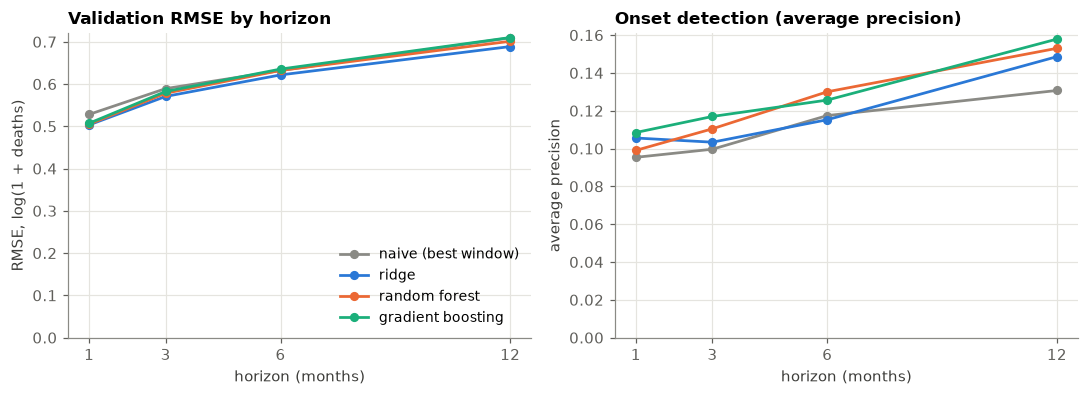

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
for model, c in COLORS.items():
    sub = leader[leader["model"] == model]
    axes[0].plot(sub["horizon"], sub["rmse"], marker="o", markersize=5, color=c, label=model)
    o = onset[onset["model"] == model]
    axes[1].plot(o["horizon"], o["average precision"], marker="o", markersize=5, color=c, label=model)
axes[0].set_title("Validation RMSE by horizon"); axes[0].set_ylabel("RMSE, log(1 + deaths)")
axes[1].set_title("Onset detection (average precision)"); axes[1].set_ylabel("average precision")
for ax in axes:
    ax.set_xticks(HORIZONS); ax.set_xlabel("horizon (months)"); ax.set_ylim(0, None)
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
plt.tight_layout(); plt.show()

## 7. Save the tuned configurations

Writes `results/best_configs.json` — the configurations to refit on all data through 2020 for the single final test evaluation. Nothing is scored on 2021–2025 here.

In [11]:
out = {}
for h in HORIZONS:
    out[str(h)] = {"naive_window": int(NAIVE_BEST[h])}
    for name in FAMILIES:
        i = int(best.loc[(h, name), "config_id"])
        out[str(h)][name] = {"config_id": i, "mean_val_rmse": float(best.loc[(h, name), "rmse"]),
                             "params": {k: to_native(v) for k, v in CONFIGS[name][i].items()}}
path = RESULTS / ("best_configs_quicktest.json" if QUICK_TEST else "best_configs.json")
path.write_text(json.dumps(out, indent=2), encoding="utf-8")
print("Saved", path.relative_to(ROOT))

Saved results\best_configs.json


## 8. Reading the results

Fill in after the full run. Things to check before drawing any conclusion:

- **Is the gap over the tuned naive baseline larger than the spread across folds?** Compare `skill` with the fold standard deviation.
- **Do the models gain on onset and continuation rows, or only on the quiet majority?** The by-row-type tables answer this.
- **Does skill hold up as the horizon grows?** A model with real memory should lose less than the naive baseline.
- **Is a configuration at the edge of its search range?** If the best ridge `alpha` or forest depth sits at a boundary, widen the range and re-run.

The reservoir models (notebooks to come) will be added to this same table, scored on the same folds with the same tuning budget.